In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report)

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Adult Data.csv to Adult Data.csv


In [ ]:
import pandas as pd
import io
df = pd.read_csv(io.BytesIO(uploaded["Adult Data.csv"]))
print(df)

       39          State-gov   77516    Bachelors   13        Never-married  \
0      50   Self-emp-not-inc   83311    Bachelors   13   Married-civ-spouse   
1      38            Private  215646      HS-grad    9             Divorced   
2      53            Private  234721         11th    7   Married-civ-spouse   
3      28            Private  338409    Bachelors   13   Married-civ-spouse   
4      37            Private  284582      Masters   14   Married-civ-spouse   
...    ..                ...     ...          ...  ...                  ...   
32555  27            Private  257302   Assoc-acdm   12   Married-civ-spouse   
32556  40            Private  154374      HS-grad    9   Married-civ-spouse   
32557  58            Private  151910      HS-grad    9              Widowed   
32558  22            Private  201490      HS-grad    9        Never-married   
32559  52       Self-emp-inc  287927      HS-grad    9   Married-civ-spouse   

             Adm-clerical   Not-in-family   White  

In [ ]:
print(df.head())

   39          State-gov   77516   Bachelors   13        Never-married  \
0  50   Self-emp-not-inc   83311   Bachelors   13   Married-civ-spouse   
1  38            Private  215646     HS-grad    9             Divorced   
2  53            Private  234721        11th    7   Married-civ-spouse   
3  28            Private  338409   Bachelors   13   Married-civ-spouse   
4  37            Private  284582     Masters   14   Married-civ-spouse   

         Adm-clerical   Not-in-family   White     Male   2174   0   40  \
0     Exec-managerial         Husband   White     Male      0   0   13   
1   Handlers-cleaners   Not-in-family   White     Male      0   0   40   
2   Handlers-cleaners         Husband   Black     Male      0   0   40   
3      Prof-specialty            Wife   Black   Female      0   0   40   
4     Exec-managerial            Wife   White   Female      0   0   40   

    United-States   <=50K  
0   United-States   <=50K  
1   United-States   <=50K  
2   United-States   <=50K 

In [ ]:

import pandas as pd

df = pd.read_csv("Adult Data.csv", header=None, skipinitialspace=True)

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

df.columns = columns

print("Dataset loaded successfully!")
print("Shape of dataset:", df.shape)

df.head()


Dataset loaded successfully!
Shape of dataset: (32561, 15)


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [ ]:
print(df.describe())

                 39         77516            13          2174             0  \
count  32560.000000  3.256000e+04  32560.000000  32560.000000  32560.000000   
mean      38.581634  1.897818e+05     10.080590   1077.615172     87.306511   
std       13.640642  1.055498e+05      2.572709   7385.402999    402.966116   
min       17.000000  1.228500e+04      1.000000      0.000000      0.000000   
25%       28.000000  1.178315e+05      9.000000      0.000000      0.000000   
50%       37.000000  1.783630e+05     10.000000      0.000000      0.000000   
75%       48.000000  2.370545e+05     12.000000      0.000000      0.000000   
max       90.000000  1.484705e+06     16.000000  99999.000000   4356.000000   

                 40  
count  32560.000000  
mean      40.437469  
std       12.347618  
min        1.000000  
25%       40.000000  
50%       40.000000  
75%       45.000000  
max       99.000000  


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32560 entries, 0 to 32559
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   39              32560 non-null  int64 
 1    State-gov      32560 non-null  object
 2    77516          32560 non-null  int64 
 3    Bachelors      32560 non-null  object
 4    13             32560 non-null  int64 
 5    Never-married  32560 non-null  object
 6    Adm-clerical   32560 non-null  object
 7    Not-in-family  32560 non-null  object
 8    White          32560 non-null  object
 9    Male           32560 non-null  object
 10   2174           32560 non-null  int64 
 11   0              32560 non-null  int64 
 12   40             32560 non-null  int64 
 13   United-States  32560 non-null  object
 14   <=50K          32560 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB
None


In [ ]:
print(df.shape)

(32561, 15)


In [ ]:
print(df.dtypes)

age                int64
workclass         object
fnlwgt             int64
education         object
education_num      int64
marital_status    object
occupation        object
relationship      object
race              object
sex               object
capital_gain       int64
capital_loss       int64
hours_per_week     int64
native_country    object
income            object
dtype: object


In [ ]:

# Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check missing values percentage
missing_percent = (df.isnull().sum() / len(df)) * 100
print("\nMissing Values Percentage:")
print(missing_percent)


Missing Values:
age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

Total Missing Values: 0

Missing Values Percentage:
age               0.0
workclass         0.0
fnlwgt            0.0
education         0.0
education_num     0.0
marital_status    0.0
occupation        0.0
relationship      0.0
race              0.0
sex               0.0
capital_gain      0.0
capital_loss      0.0
hours_per_week    0.0
native_country    0.0
income            0.0
dtype: float64


In [ ]:

# Check '?' values in the dataset
print("Question mark values in each column:")
print((df.astype(str).apply(lambda col: col.str.strip() == "?")).sum())


Question mark values in each column:
age                  0
workclass         1836
fnlwgt               0
education            0
education_num        0
marital_status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital_gain         0
capital_loss         0
hours_per_week       0
native_country     583
income               0
dtype: int64


In [ ]:

# Check duplicate rows
print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 24


In [ ]:

# Remove duplicate rows
df = df.drop_duplicates()

# Check dataset shape after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)


Dataset shape after removing duplicates: (32537, 15)


In [ ]:

# Numerical columns
numerical_cols = df.select_dtypes(include=np.number).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(include="object").columns.tolist()

print("Numerical Columns:")
print(numerical_cols)

print("\nCategorical Columns:")
print(categorical_cols)


Numerical Columns:
['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical Columns:
['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


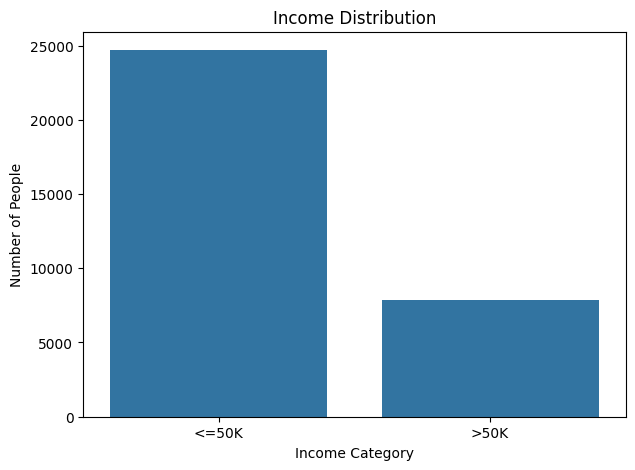

In [ ]:

# Count plot of income
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="income")

plt.title("Income Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of People")

plt.show()


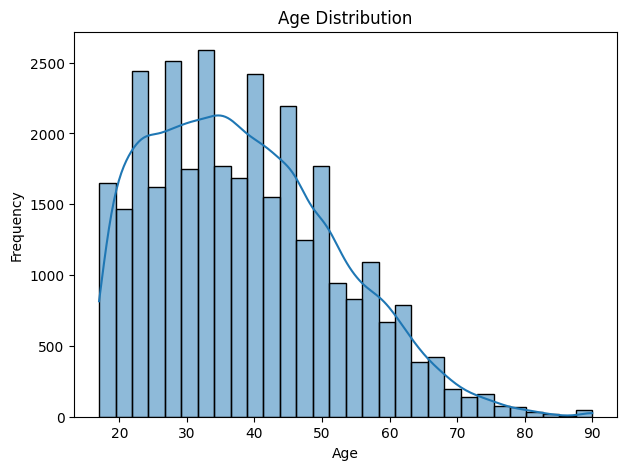

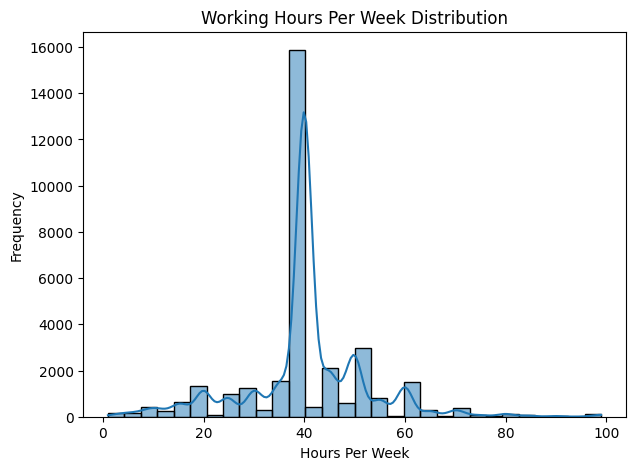

In [ ]:

# Distribution of age
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()


# Distribution of working hours
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x="hours_per_week", bins=30, kde=True)

plt.title("Working Hours Per Week Distribution")
plt.xlabel("Hours Per Week")
plt.ylabel("Frequency")

plt.show()


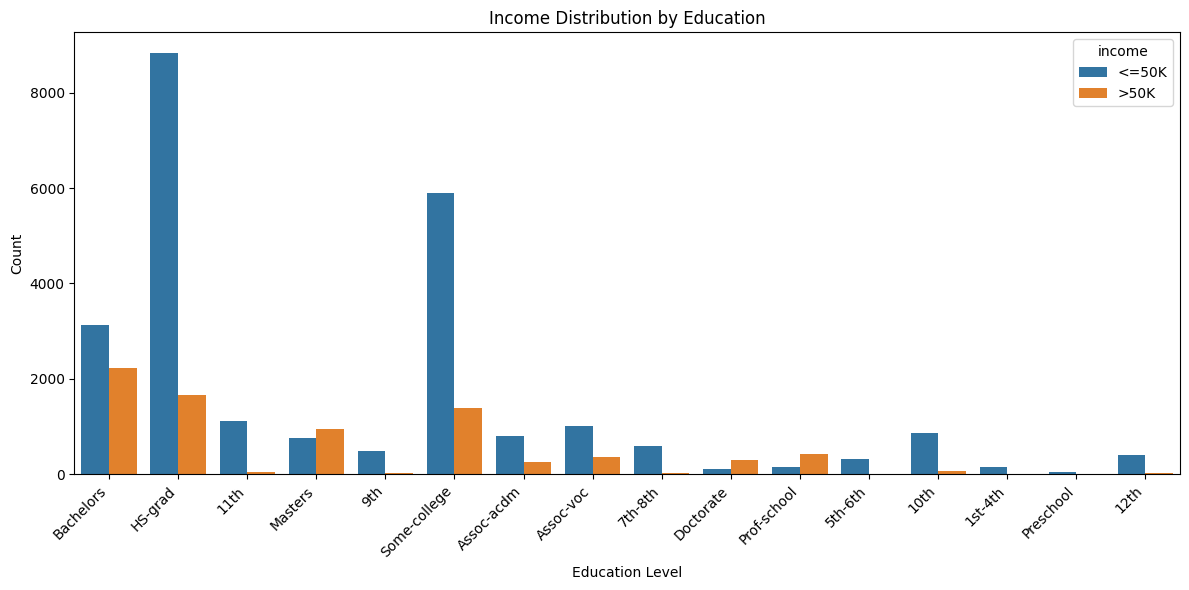

In [ ]:

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="education",
    hue="income"
)

plt.title("Income Distribution by Education")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


In [ ]:
X = df.drop("income", axis=1)
y = df["income"].astype(str).str.strip()

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nIncome Categories:")
print(y.value_counts())


Features Shape: (32537, 14)
Target Shape: (32537,)

Income Categories:
income
<=50K    24698
>50K      7839
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (26029, 14)
X_test: (6508, 14)
y_train: (26029,)
y_test: (6508,)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numerical_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()

print("Numerical columns:", numerical_cols)
print("\nCategorical columns:", categorical_cols)

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nTraining data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)


Numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']

Training data shape: (26029, 108)
Testing data shape: (6508, 108)


In [ ]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

print("Income classes:", label_encoder.classes_)
print("Training target shape:", y_train_encoded.shape)
print("Testing target shape:", y_test_encoded.shape)


Income classes: ['<=50K' '>50K']
Training target shape: (26029,)
Testing target shape: (6508,)


In [ ]:

from sklearn.linear_model import LogisticRegression

# Create the model
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
lr_model.fit(X_train_processed, y_train_encoded)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [ ]:

# Predict on test data
y_pred_lr = lr_model.predict(X_test_processed)

print("First 10 actual values:", y_test_encoded[:10])
print("First 10 predicted values:", y_pred_lr[:10])


First 10 actual values: [0 1 0 0 0 0 0 0 0 1]
First 10 predicted values: [0 1 0 0 0 0 0 0 0 0]


Logistic Regression Accuracy: 85.79 %

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      4940
        >50K       0.74      0.63      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.81      0.78      0.79      6508
weighted avg       0.85      0.86      0.85      6508



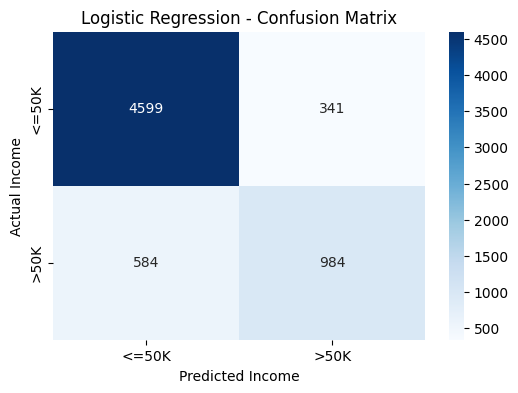

In [ ]:

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Calculate accuracy
accuracy_lr = accuracy_score(y_test_encoded, y_pred_lr)

print("Logistic Regression Accuracy:",
      round(accuracy_lr * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_lr,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test_encoded, y_pred_lr)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Create the model
dt_model = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

# Train the model
dt_model.fit(X_train_processed, y_train_encoded)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


Decision Tree Accuracy: 86.46 %

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.91      4940
        >50K       0.79      0.60      0.68      1568

    accuracy                           0.86      6508
   macro avg       0.83      0.77      0.80      6508
weighted avg       0.86      0.86      0.86      6508



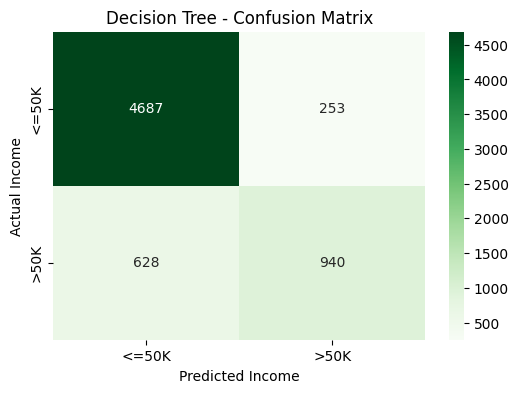

In [ ]:

# Make predictions
y_pred_dt = dt_model.predict(X_test_processed)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test_encoded, y_pred_dt)

print("Decision Tree Accuracy:",
      round(accuracy_dt * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_dt,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm_dt = confusion_matrix(y_test_encoded, y_pred_dt)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [ ]:

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy (%)": [
        accuracy_lr * 100,
        accuracy_dt * 100
    ]
})

display(
    model_comparison.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)
)


,Model,Accuracy (%)
0,Decision Tree,86.462815
1,Logistic Regression,85.786724


In [ ]:

from sklearn.ensemble import RandomForestClassifier

# Create the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train_encoded)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


Random Forest Accuracy: 86.85 %

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.88      0.95      0.92      4940
        >50K       0.80      0.60      0.69      1568

    accuracy                           0.87      6508
   macro avg       0.84      0.78      0.80      6508
weighted avg       0.86      0.87      0.86      6508



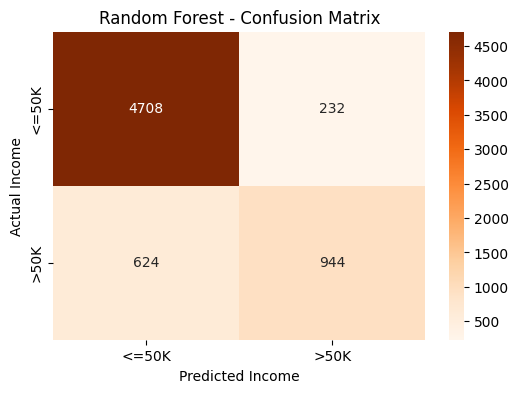

In [ ]:

# Predict on test data
y_pred_rf = rf_model.predict(X_test_processed)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test_encoded, y_pred_rf)

print("Random Forest Accuracy:",
      round(accuracy_rf * 100, 2), "%")

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test_encoded,
    y_pred_rf,
    target_names=label_encoder.classes_,
    zero_division=0
))

# Confusion matrix
cm_rf = confusion_matrix(y_test_encoded, y_pred_rf)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Income")
plt.ylabel("Actual Income")
plt.title("Random Forest - Confusion Matrix")
plt.show()


In [ ]:

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Get feature importance from Random Forest
importance = rf_model.feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

# Sort by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
display(feature_importance.head(15))


,Feature,Importance
3,num__capital_gain,0.139504
33,cat__marital_status_Married-civ-spouse,0.131731
2,num__education_num,0.099937
0,num__age,0.081023
53,cat__relationship_Husband,0.072367
5,num__hours_per_week,0.053915
35,cat__marital_status_Never-married,0.036644
1,num__fnlwgt,0.035191
4,num__capital_loss,0.033471
42,cat__occupation_Exec-managerial,0.024163


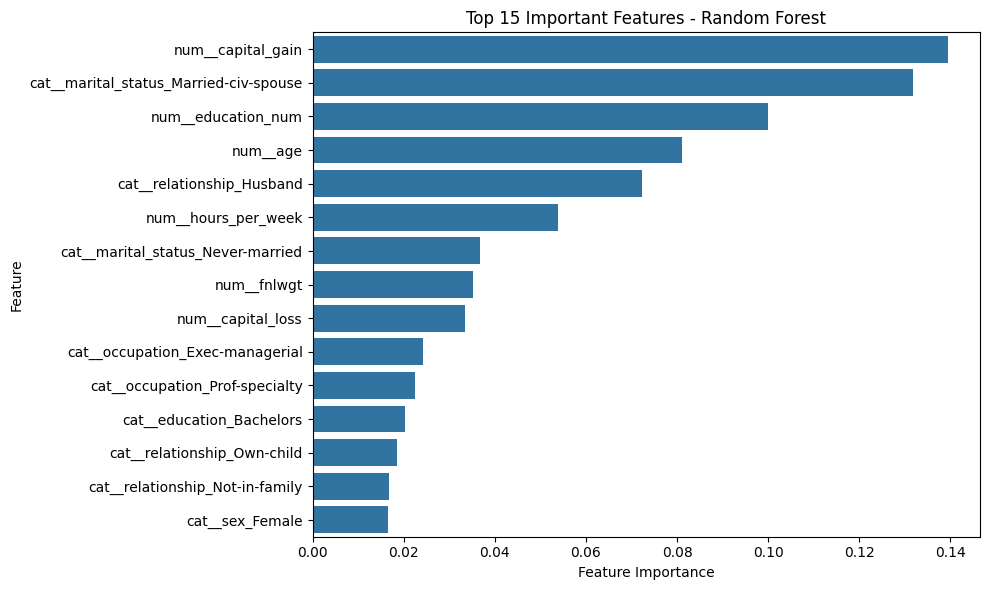

In [ ]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:

import joblib

joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")
joblib.dump(label_encoder, "label_encoder.pkl")

print("Model and preprocessing files saved successfully!")


Model and preprocessing files saved successfully!


In [ ]:

from google.colab import files

files.download("random_forest_model.pkl")
files.download("preprocessor.pkl")
files.download("label_encoder.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Create one new person's data
new_person = pd.DataFrame([{
    "age": 35,
    "workclass": "Private",
    "fnlwgt": 150000,
    "education": "Bachelors",
    "education_num": 13,
    "marital_status": "Married-civ-spouse",
    "occupation": "Exec-managerial",
    "relationship": "Husband",
    "race": "White",
    "sex": "Male",
    "capital_gain": 0,
    "capital_loss": 0,
    "hours_per_week": 40,
    "native_country": "United-States"
}])

# Apply the same preprocessing used during training
new_person_processed = preprocessor.transform(new_person)

# Predict income category
prediction = rf_model.predict(new_person_processed)

# Convert prediction back to the original label
predicted_income = label_encoder.inverse_transform(prediction)

print("Predicted Income Category:", predicted_income[0])


Predicted Income Category: >50K


In [ ]:

import os

print("Saved files:")

for filename in [
    "random_forest_model.pkl",
    "preprocessor.pkl",
    "label_encoder.pkl"
]:
    print(filename, "->", os.path.exists(filename))


Saved files:
random_forest_model.pkl -> True
preprocessor.pkl -> True
label_encoder.pkl -> True
